In [1]:
from fastai.vision.all import *

/home/juwiragiye/dev/mit15.773/fastbook/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Download the dataset

In [2]:
path = untar_data(URLs.PETS)/'images'

## Explore the dataset

In [3]:
files = get_image_files(path)
len(files)

7390

<Axes: >

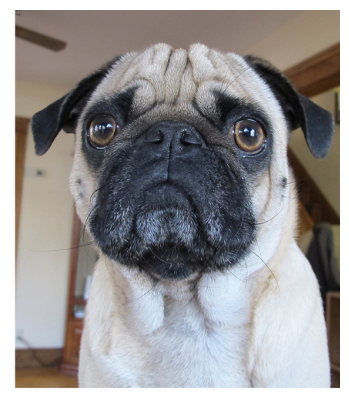

In [4]:
img = PILImage.create(files[0])
img.show()

## Prepare the data

In [5]:
pets = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=using_attr(
        RegexLabeller(r'(.+)_\d+.jpg$'),
        'name'
    ),
    item_tfms=Resize(224),
    batch_tfms=aug_transforms()
)
dls = pets.dataloaders(path, bs=32)
    

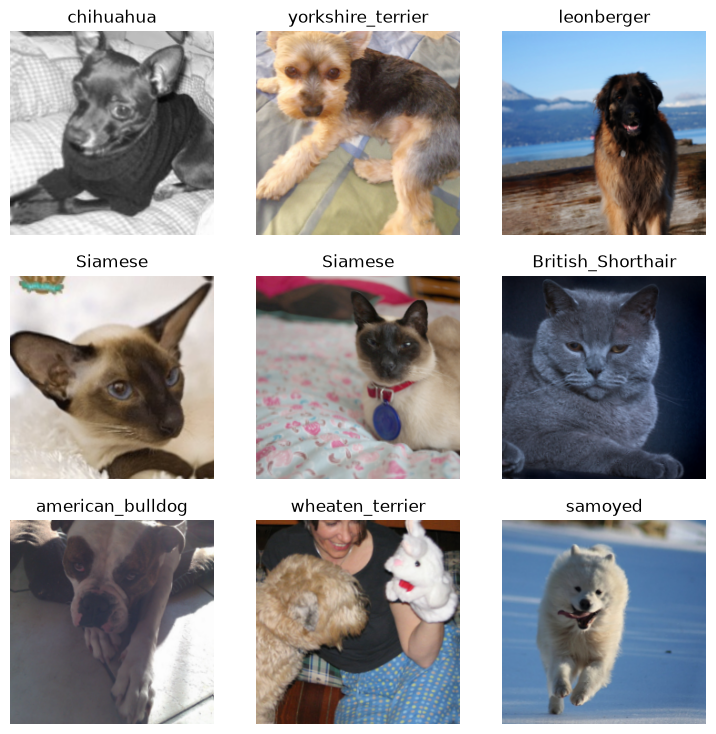

In [6]:
dls.show_batch()

## Train the model

In [7]:
learn = vision_learner(
    dls,
    resnet34,
    metrics=[accuracy, error_rate]
)
learn.fine_tune(6)

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.999485,0.355590,0.888363,0.111637,00:21


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.501667,0.321026,0.893099,0.106901,00:26
1,0.513461,0.375278,0.883627,0.116373,00:26
2,0.437363,0.332093,0.903248,0.096752,00:26
3,0.259250,0.292198,0.916779,0.083221,00:25
4,0.155920,0.256538,0.926252,0.073748,00:25
5,0.096646,0.244562,0.928281,0.071719,00:25


## Evaluate the model

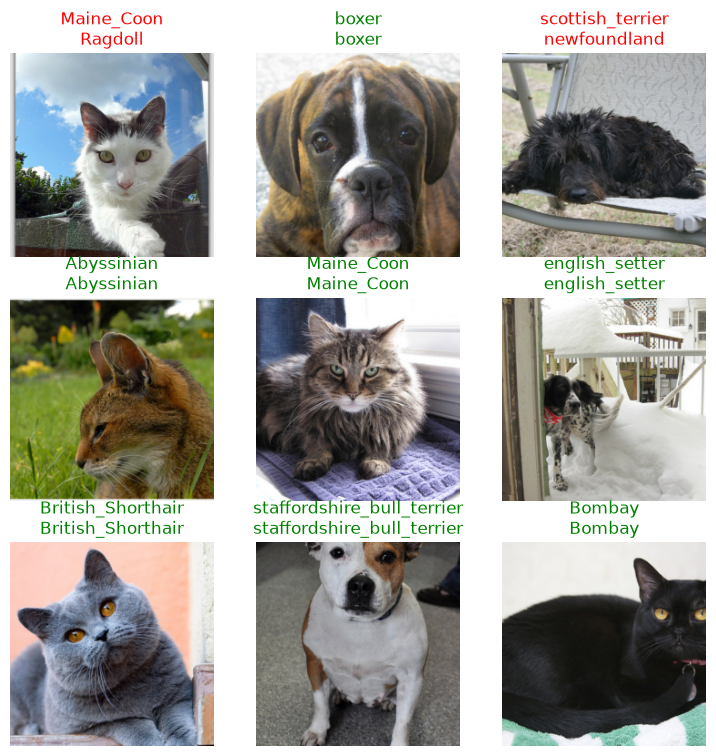

In [8]:
learn.show_results()

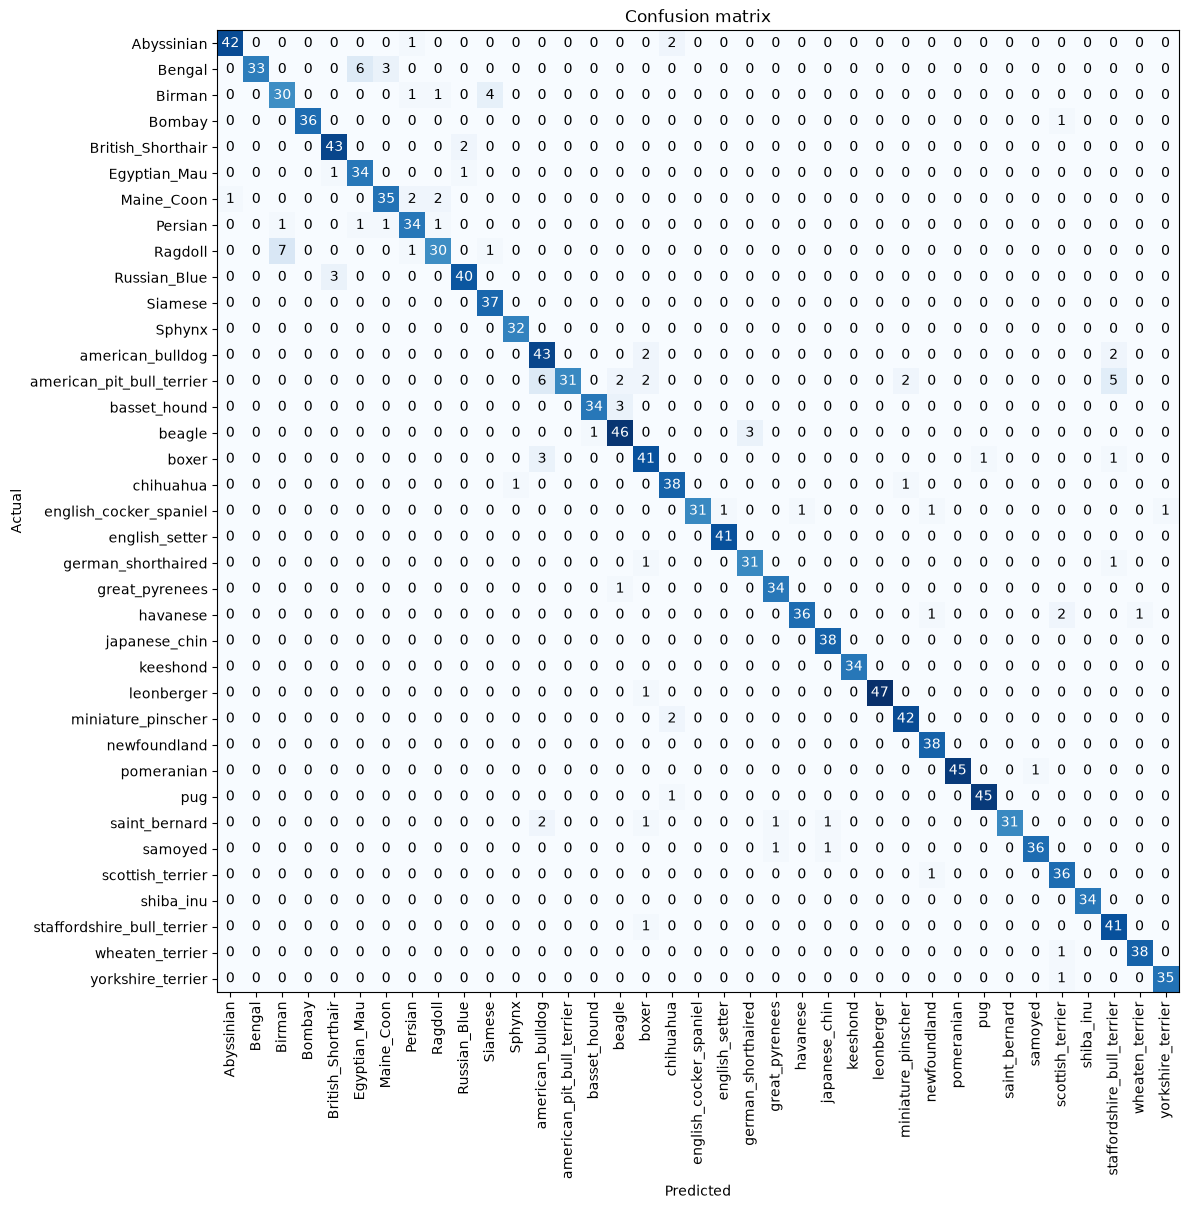

In [9]:
interp = ClassificationInterpretation.from_learner(learn)

interp.plot_confusion_matrix(figsize=(12, 12))

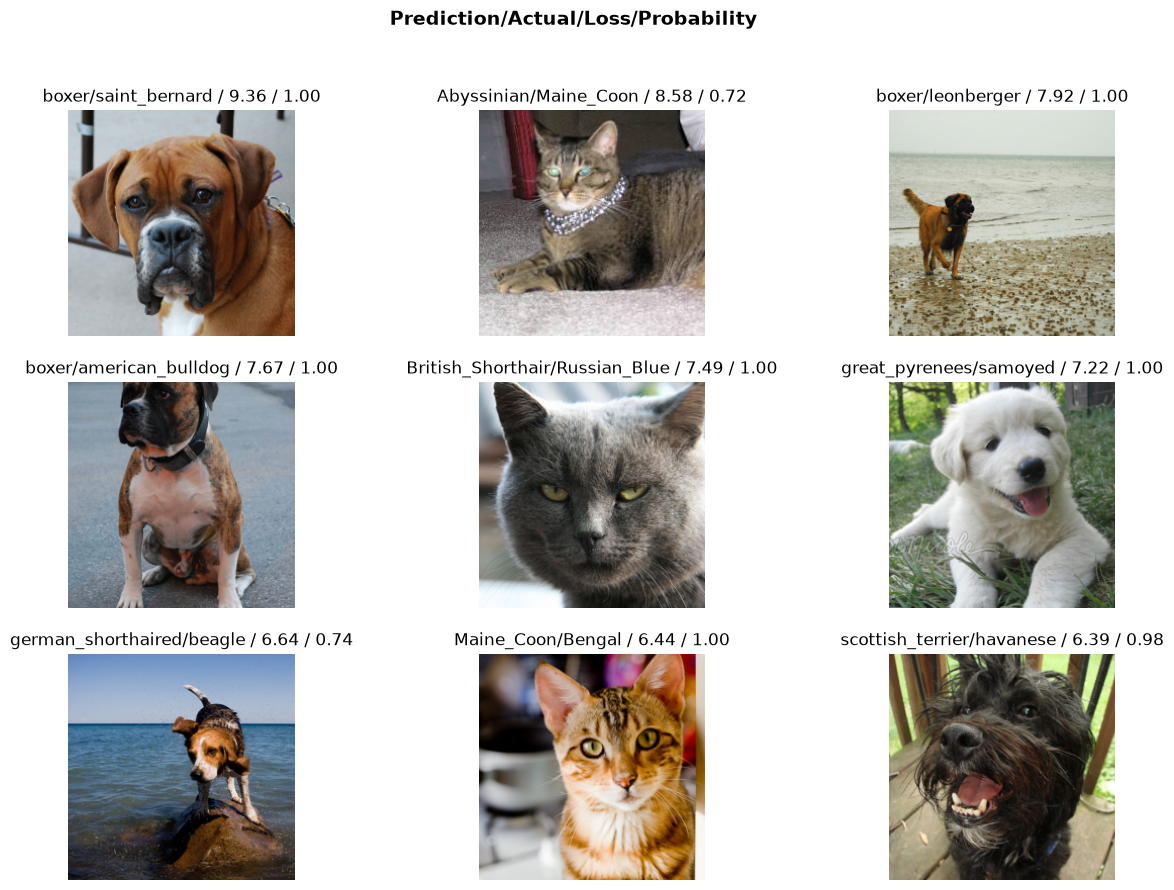

In [10]:
interp.plot_top_losses(9, figsize=(15, 10))

In [11]:
img = PILImage.create(files[0])

breed, index, probabilities = learn.predict(img)

print("Breed:", breed)
print("Confidence:", float(probabilities[index]))

Breed: pug
Confidence: 0.9999990463256836


In [12]:
export_dir = Path("../exports")
export_dir.mkdir(exist_ok=True)

learn.export(
    (export_dir / "pets.pkl").resolve()
)